## C1 - WEEK 1

- Adrià Cantarero Carreras (1809773@uab.cat)
- Ivan Martin Campoy (1673246@uab.cat)
- Irene Pumares Benaiges (1810704@uab.cat)
- Lavish Ramchandani (1691238@uab.cat)

In [1]:
import sys
sys.path.append("..")  # repo root, for utils/
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np

## TASK 1: Compute image descriptors

In [2]:
#database and qsd1 paths

bbdd_path = "./data/BBDD"
qsd1_path = "./data/qsd1_w1"

COLOR_SPACES = {
    "GRAY": cv2.COLOR_BGR2GRAY,
    "RGB":  cv2.COLOR_BGR2RGB,
    "HSV":  cv2.COLOR_BGR2HSV,
    "LAB":  cv2.COLOR_BGR2LAB,
    "YCRCB": cv2.COLOR_BGR2YCrCb,
}

#value range of every channel. OpenCV hue goes from 0 to 179, not to 255
CHANNEL_RANGES = {
    "GRAY":  [(0, 256)],
    "RGB":   [(0, 256)] * 3,
    "HSV":   [(0, 180), (0, 256), (0, 256)],
    "LAB":   [(0, 256)] * 3,
    "YCRCB": [(0, 256)] * 3,
}

#descriptors
bbdd_descriptors = []
qsd1_descriptors = []


#----------------------------------------------------------------------------------
#sort files
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

#sort bbdd files
bbdd_files = [f for f in os.listdir(bbdd_path) if f.lower().endswith(".jpg")]
bbdd_files.sort(key=return_number)

#sort qsd1 files
qsd1_files = [f for f in os.listdir(qsd1_path) if f.lower().endswith(".jpg")]
qsd1_files.sort(key=return_number)

#id of an image = number in its file name (bbdd_00007.jpg -> 7)
def image_id(file_name):
    return int(re.findall(r'\d+', file_name)[-1])

bbdd_ids = np.array([image_id(f) for f in bbdd_files])
qsd1_ids = np.array([image_id(f) for f in qsd1_files])
#----------------------------------------------------------------------------------

#feature extraction function

def compute_1d_Histogram(image, color_space = "HSV", bins = 32):
    if color_space in COLOR_SPACES:
        img_converted = cv2.cvtColor(image, COLOR_SPACES[color_space])
    else:
        img_converted = image #in case it is already in BGR

    ranges = CHANNEL_RANGES.get(color_space, [(0, 256)] * 3)

    #calc hist
    if len(img_converted.shape) == 2: #grayscale
        hist = cv2.calcHist([img_converted], [0], None, [bins], list(ranges[0]))
        descriptor = hist.flatten() #1D array, shape (bins,)

    elif len(img_converted.shape) == 3:
        channel_hists = []

        for channel in range(3):
            ch_hist = cv2.calcHist([img_converted], [channel], None, [bins], list(ranges[channel]))
            ch_hist = ch_hist.flatten()

            #normalize each channel 
            total = np.sum(ch_hist)
            if total > 0:
                ch_hist = ch_hist / total

            channel_hists.append(ch_hist)

        descriptor = np.concatenate(channel_hists) #stack all the channels into 1D array

    #normalization
    total_pixels = np.sum(descriptor)
    if total_pixels > 0:
        descriptor = descriptor / total_pixels

    return descriptor

#----------------------------------------------------------------------------------

#read one image
def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")   #skipping it would shift every index after it and break the ground truth
    return image

#load images iteratively bbdd set
bbdd_imgs = []
for file_name in bbdd_files:
    img_path = os.path.join(bbdd_path, file_name)
    image = read_image(img_path)
    bbdd_imgs.append(image)

##load images iteratively qsd1 set
qsd1_imgs = []
for file_name in qsd1_files:
    img_path = os.path.join(qsd1_path, file_name)
    image = read_image(img_path)
    qsd1_imgs.append(image)

In [14]:
#comparison

#METHOD 1: Grayscale
bbdd_desc_m1 = [compute_1d_Histogram(im, color_space="GRAY", bins=32) for im in bbdd_imgs]
qsd1_desc_m1 = [compute_1d_Histogram(im, color_space="GRAY", bins=32) for im in qsd1_imgs]

bbdd_desc_m1 = np.array(bbdd_desc_m1)  #shape: (287, 32)
qsd1_desc_m1 = np.array(qsd1_desc_m1)  #shape: (30, 32)

print(f" Shape of bbdd_desc_m1: {bbdd_desc_m1.shape}")
print(f" Shape of qsd1_desc_m1: {qsd1_desc_m1.shape}\n")

#METHOD 2: HSV
bbdd_desc_m2 = [compute_1d_Histogram(im, color_space="HSV", bins=32) for im in bbdd_imgs]
qsd1_desc_m2 = [compute_1d_Histogram(im, color_space="HSV", bins=32) for im in qsd1_imgs]

bbdd_desc_m2 = np.array(bbdd_desc_m2)  #shape: (287, 96)
qsd1_desc_m2 = np.array(qsd1_desc_m2)  #shape: (30, 96)

print(f" Shape of bbdd_desc_m2: {bbdd_desc_m2.shape}")
print(f" Shape of qsd1_desc_m2: {qsd1_desc_m2.shape}")


#EXTRA METHODS
from utils.extra_descriptors import *

#METHOD 3: Chroma only, LAB (a + b channels, no lightness)
bbdd_desc_m3 = [hist_chroma(im, color_space="LAB", bins=32) for im in bbdd_imgs]
qsd1_desc_m3 = [hist_chroma(im, color_space="LAB", bins=32) for im in qsd1_imgs]

bbdd_desc_m3 = np.array(bbdd_desc_m3)  #shape: (287, 64)
qsd1_desc_m3 = np.array(qsd1_desc_m3)  #shape: (30, 64)

print(f" Shape of bbdd_desc_m3: {bbdd_desc_m3.shape}")
print(f" Shape of qsd1_desc_m3: {qsd1_desc_m3.shape}\n")

#METHOD 4: Chroma only, HSV (H + S channels, no value)
bbdd_desc_m4 = [hist_chroma(im, color_space="HSV", bins=32) for im in bbdd_imgs]
qsd1_desc_m4 = [hist_chroma(im, color_space="HSV", bins=32) for im in qsd1_imgs]

bbdd_desc_m4 = np.array(bbdd_desc_m4)  #shape: (287, 64)
qsd1_desc_m4 = np.array(qsd1_desc_m4)  #shape: (30, 64)

print(f" Shape of bbdd_desc_m4: {bbdd_desc_m4.shape}")
print(f" Shape of qsd1_desc_m4: {qsd1_desc_m4.shape}\n")

#METHOD 5: CLAHE on lightness + LAB histogram
bbdd_desc_m5 = [hist_clahe_lab(im, bins=32) for im in bbdd_imgs]
qsd1_desc_m5 = [hist_clahe_lab(im, bins=32) for im in qsd1_imgs]

bbdd_desc_m5 = np.array(bbdd_desc_m5)  #shape: (287, 96)
qsd1_desc_m5 = np.array(qsd1_desc_m5)  #shape: (30, 96)

print(f" Shape of bbdd_desc_m5: {bbdd_desc_m5.shape}")
print(f" Shape of qsd1_desc_m5: {qsd1_desc_m5.shape}\n")

#METHOD 6: Saturation-weighted hue histogram
bbdd_desc_m6 = [hist_hue_weighted(im, bins=36) for im in bbdd_imgs]
qsd1_desc_m6 = [hist_hue_weighted(im, bins=36) for im in qsd1_imgs]

bbdd_desc_m6 = np.array(bbdd_desc_m6)  #shape: (287, 36)
qsd1_desc_m6 = np.array(qsd1_desc_m6)  #shape: (30, 36)

print(f" Shape of bbdd_desc_m6: {bbdd_desc_m6.shape}")
print(f" Shape of qsd1_desc_m6: {qsd1_desc_m6.shape}\n")

#METHOD 7: Gradient orientation histogram
# bbdd_desc_m7 = [hist_gradient_orientation(im, bins=18) for im in bbdd_imgs]
# qsd1_desc_m7 = [hist_gradient_orientation(im, bins=18) for im in qsd1_imgs]

# bbdd_desc_m7 = np.array(bbdd_desc_m7)  #shape: (287, 18)
# qsd1_desc_m7 = np.array(qsd1_desc_m7)  #shape: (30, 18)

# print(f" Shape of bbdd_desc_m7: {bbdd_desc_m7.shape}")
# print(f" Shape of qsd1_desc_m7: {qsd1_desc_m7.shape}\n")

#METHOD 8: Global LBP histogram
bbdd_desc_m8 = [hist_lbp(im) for im in bbdd_imgs]
qsd1_desc_m8 = [hist_lbp(im) for im in qsd1_imgs]

bbdd_desc_m8 = np.array(bbdd_desc_m8)  #shape: (287, 256)
qsd1_desc_m8 = np.array(qsd1_desc_m8)  #shape: (30, 256)

print(f" Shape of bbdd_desc_m8: {bbdd_desc_m8.shape}")
print(f" Shape of qsd1_desc_m8: {qsd1_desc_m8.shape}")

 Shape of bbdd_desc_m1: (287, 32)
 Shape of qsd1_desc_m1: (30, 32)

 Shape of bbdd_desc_m2: (287, 96)
 Shape of qsd1_desc_m2: (30, 96)
 Shape of bbdd_desc_m3: (287, 64)
 Shape of qsd1_desc_m3: (30, 64)

 Shape of bbdd_desc_m4: (287, 64)
 Shape of qsd1_desc_m4: (30, 64)

 Shape of bbdd_desc_m5: (287, 96)
 Shape of qsd1_desc_m5: (30, 96)

 Shape of bbdd_desc_m6: (287, 36)
 Shape of qsd1_desc_m6: (30, 36)

 Shape of bbdd_desc_m8: (287, 256)
 Shape of qsd1_desc_m8: (30, 256)


- - -
## Task 2: Similarity measures
- - -

In [15]:
eps = 1e-10  # small value to avoid division by zero


def euclidean_distance(x, y):
    return np.sqrt(np.sum((x - y) ** 2, axis=-1))

def L1_distance(x, y):
    return np.sum(np.abs(x - y), axis=-1)

def chi_squared_distance(x, y):
    return 0.5 * np.sum(((x - y) ** 2) / (x + y + eps), axis=-1)

def jensen_shannon_distance(x, y):
    m = 0.5 * (x + y)
    kl_x = np.sum(x * np.log((x + eps) / (m + eps)), axis=-1)
    kl_y = np.sum(y * np.log((y + eps) / (m + eps)), axis=-1)
    return np.sqrt(np.clip(0.5 * (kl_x + kl_y), 0, None))

def emd_distance(x, y, bins):
    n_hist = x.shape[-1] // bins
    cx = np.cumsum(x.reshape(x.shape[:-1] + (n_hist, bins)), axis=-1)
    cy = np.cumsum(y.reshape(y.shape[:-1] + (n_hist, bins)), axis=-1)
    return np.sum(np.abs(cx - cy), axis=(-2, -1))

#all the measures below are written as distances (smaller = more similar) because the retrieval step will rank every measure 
#with the same rule (sort ascending and take the first k)

def histogram_intersection_distance(x, y):
    return 1.0 - np.sum(np.minimum(x, y), axis=-1)

def hellinger_distance(x, y):
    return (1.0 / np.sqrt(2.0)) * np.sqrt(np.sum((np.sqrt(np.clip(x, 0, None)) - np.sqrt(np.clip(y, 0, None))) ** 2, axis=-1))

def cosine_distance(x, y):
    return 1.0 - np.sum(x * y, axis=-1) / (np.linalg.norm(x, axis=-1) * np.linalg.norm(y, axis=-1) + eps)

def correlation_distance(x, y):
    xc = x - np.mean(x, axis=-1, keepdims=True)
    yc = y - np.mean(y, axis=-1, keepdims=True)
    return 1.0 - np.sum(xc * yc, axis=-1) / (np.linalg.norm(xc, axis=-1) * np.linalg.norm(yc, axis=-1) + eps)

MEASURES = {
    "euclidean":      euclidean_distance,
    "L1":             L1_distance,
    "chi2":           chi_squared_distance,
    "intersection":   histogram_intersection_distance,
    "hellinger":      hellinger_distance,
    "cosine":         cosine_distance,
    "correlation":    correlation_distance,
    "jensen_shannon": jensen_shannon_distance,
    "emd":            emd_distance,
}

- - -
## Task 3: For each image in QSD1, evaluate all descriptor and distance combinations

For each QSD1 query, rank BBDD images using each descriptor-distance pair. Compare methods with MAP@1 and MAP@5, and retain each query's top-five IDs and AP scores. EMD uses the bin count associated with each descriptor.
- - -

In [16]:
# import ml_metrics as metrics #Couldn't install it so I copied the code from the git

import numpy as np

#code from https://github.com/benhamner/Metrics/blob/master/Python/ml_metrics/custom/kdd_average_precision.py
def kdd_apk(actual, predicted, k=10):
    """
    Computes the average precision at k for Track 1 of the 2012 KDD Cup.

    This modified version uses the number of actual clicks as the denominator,
    regardless of k.

    This function computes the average prescision at k between two lists of
    items.

    Parameters
    ----------
    actual : list
             A list of elements that are to be predicted (order doesn't matter)
    predicted : list
                A list of predicted elements (order does matter)
    k : int, optional
        The maximum number of predicted elements

    Returns
    -------
    score : double
            The average precision at k over the input lists

    """
    if len(predicted)>k:
        predicted = predicted[:k]

    score = 0.0
    num_hits = 0.0

    for i,p in enumerate(predicted):
        if p in actual and p not in predicted[:i]: #p not in predicted[:i] is to avoid no extra marks for repeating
            num_hits += 1.0
            score += num_hits / (i+1.0)

    if not actual:
        return 0.0

    return score / len(actual)

def kdd_mapk(actual, predicted, k=10):
    """
    Computes the mean average precision at k for Track 1 of the 2012 KDD Cup.

    This modified version uses the number of actual clicks as the denominator,
    regardless of k.

    This function computes the mean average prescision at k between two lists
    of lists of items.

    Parameters
    ----------
    actual : list
             A list of lists of elements that are to be predicted 
             (order doesn't matter in the lists)
    predicted : list
                A list of lists of predicted elements
                (order matters in the lists)
    k : int, optional
        The maximum number of predicted elements

    Returns
    -------
    score : double
            The mean average precision at k over the input lists

    """
    return np.mean([kdd_apk(a,p,k) for a,p in zip(actual, predicted)])


#apk is like the average precision of hits at k items
#but mapk looks in the entire dataset

In [ ]:
import pandas as pd
from IPython.display import display

gt_path = os.path.join(qsd1_path, "gt_corresps.pkl")
with open(gt_path, "rb") as f:
    gt_corresps = pickle.load(f)

num_queries = len(gt_corresps)
assert num_queries == len(qsd1_files), (
    f"GT has {num_queries} entries but QSD1 has {len(qsd1_files)} images."
)
assert len(bbdd_ids) == len(bbdd_files), "BBDD IDs do not match the database files."
actual_ids = [[int(item) for item in query_gt] for query_gt in gt_corresps]


In [ ]:
from functools import partial

# One parameter grid evaluates every descriptor configuration and distance measure.
descriptor_grid = []

for bins in (16, 32, 64):
    descriptor_grid.extend([
        ("M1 Grayscale", f"bins={bins}", partial(compute_1d_Histogram, color_space="GRAY", bins=bins), bins),
        ("M2 HSV", f"bins={bins}", partial(compute_1d_Histogram, color_space="HSV", bins=bins), bins),
        ("M3 LAB chroma", f"bins={bins}", partial(hist_chroma, color_space="LAB", bins=bins), bins),
        ("M4 HSV chroma", f"bins={bins}", partial(hist_chroma, color_space="HSV", bins=bins), bins),
    ])
    for clip_limit in (1.0, 2.0, 4.0):
        descriptor_grid.append((
            "M5 CLAHE LAB",
            f"bins={bins}, clip={clip_limit}, tile=8",
            partial(hist_clahe_lab, bins=bins, clip=clip_limit, tile=8),
            bins,
        ))

for bins in (18, 36, 72):
    descriptor_grid.append(("M6 Weighted hue", f"bins={bins}", partial(hist_hue_weighted, bins=bins), bins))

for image_size in (128, 256, 384):
    descriptor_grid.append(("M8 LBP", f"size={image_size}", partial(hist_lbp, size=image_size), 256))

assert len(descriptor_grid) == 27

grid_summary_rows, grid_query_rows = [], []

for descriptor_name, parameters, descriptor_fn, emd_bins in descriptor_grid:
    db_desc = np.asarray([descriptor_fn(image) for image in bbdd_imgs])
    q_desc = np.asarray([descriptor_fn(image) for image in qsd1_imgs])
    assert db_desc.ndim == 2 and q_desc.shape[1] == db_desc.shape[1]
    assert len(db_desc) == len(bbdd_ids) and len(q_desc) == len(actual_ids)

    for distance_name, distance_fn in MEASURES.items():
        predictions = []
        for query_index, query_descriptor in enumerate(q_desc):
            if distance_name == "emd":
                distances = distance_fn(query_descriptor, db_desc, bins=emd_bins)
            else:
                distances = distance_fn(query_descriptor, db_desc)
            top5_ids = [int(image_id) for image_id in bbdd_ids[np.argsort(distances)[:5]]]
            predictions.append(top5_ids)

            query_gt = actual_ids[query_index]
            grid_query_rows.append({
                "Descriptor": descriptor_name, "Parameters": parameters, "Distance": distance_name,
                "Query": qsd1_files[query_index], "GT IDs": query_gt,
                "Top 1 ID": top5_ids[0], "Top 5 IDs": top5_ids,
                "AP@1": kdd_apk(query_gt, top5_ids[:1], k=1),
                "AP@5": kdd_apk(query_gt, top5_ids, k=5),
            })

        grid_summary_rows.append({
            "Descriptor": descriptor_name, "Parameters": parameters, "Distance": distance_name,
            "MAP@1": kdd_mapk(actual_ids, [items[:1] for items in predictions], k=1),
            "MAP@5": kdd_mapk(actual_ids, predictions, k=5),
        })

cols = ["Descriptor", "Parameters", "Distance", "MAP@1", "MAP@5"]
leaderboard_all = (
    pd.DataFrame(grid_summary_rows)[cols]
    .sort_values(["MAP@5", "MAP@1"], ascending=False, kind="stable")
    .reset_index(drop=True)
)
leaderboard_all.insert(0, "Rank", np.arange(1, len(leaderboard_all) + 1))
query_cols = ["Descriptor", "Parameters", "Distance", "Query", "GT IDs", "Top 1 ID", "Top 5 IDs", "AP@1", "AP@5"]
per_query_all = pd.DataFrame(grid_query_rows)[query_cols]

method_id = lambda frame: frame["Descriptor"] + " | " + frame["Parameters"] + " | " + frame["Distance"]
best_two_all = leaderboard_all.head(2).copy()
best_two_queries_all = per_query_all[method_id(per_query_all).isin(set(method_id(best_two_all)))].copy()

assert len(leaderboard_all) == len(descriptor_grid) * len(MEASURES)
assert len(per_query_all) == len(leaderboard_all) * len(actual_ids)
assert len(best_two_queries_all) == 2 * len(actual_ids)

results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)
leaderboard_all.to_csv(os.path.join(results_dir, "map_at_1_5_leaderboard.csv"), index=False)
per_query_all.to_csv(os.path.join(results_dir, "all_query_retrieval_results.csv"), index=False)
best_two_queries_all.to_csv(os.path.join(results_dir, "best_two_methods_per_query.csv"), index=False)
pd.DataFrame(grid_summary_rows).to_csv(os.path.join(results_dir, "parameter_grid_search.csv"), index=False)

print(f"Grid search: {len(leaderboard_all)} configurations x distance results over {len(actual_ids)} queries")
display(leaderboard_all.head(10).round({"MAP@1": 4, "MAP@5": 4}))


In [ ]:
import matplotlib.pyplot as plt

chart_descriptors = ["M2 HSV", "M5 CLAHE LAB"]
distance_order = list(MEASURES.keys())
distance_labels = {
    "euclidean": "Euclidean",
    "L1": "L1",
    "chi2": "Chi-squared",
    "intersection": "Intersection",
    "hellinger": "Hellinger",
    "cosine": "Cosine",
    "correlation": "Correlation",
    "jensen_shannon": "Jensen-Shannon",
    "emd": "EMD",
}
chart_colors = {"M2 HSV": "#168C8C", "M5 CLAHE LAB": "#D56A4A"}
clean = lambda name: re.sub(r"^M\d+\s+", "", name)

# Fix each descriptor at its best MAP@5 parameter setting, using MAP@1 to break ties.
best_config_rows = (
    leaderboard_all.sort_values(["MAP@5", "MAP@1"], ascending=False, kind="stable")
    .drop_duplicates(subset=["Descriptor"])
    .set_index("Descriptor")
)
best_parameters = {name: best_config_rows.loc[name, "Parameters"] for name in chart_descriptors}
chart_results = leaderboard_all[
    leaderboard_all["Descriptor"].isin(chart_descriptors)
    & (leaderboard_all["Parameters"] == leaderboard_all["Descriptor"].map(best_parameters))
]
assert len(chart_results) == len(chart_descriptors) * len(distance_order)

print("Best parameter settings selected by MAP@5 (MAP@1 breaks ties):")
display(best_config_rows.loc[chart_descriptors, ["Parameters", "Distance", "MAP@1", "MAP@5"]].round({"MAP@1": 4, "MAP@5": 4}))

positions = np.arange(len(distance_order))
bar_width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharex=True, sharey=True)

for axis, metric, title in zip(
    axes,
    ["MAP@1", "MAP@5"],
    ["MAP@1: Top-1 Retrieval", "MAP@5: Top-5 Retrieval"],
):
    metric_table = (
        chart_results.pivot(index="Distance", columns="Descriptor", values=metric)
        .reindex(distance_order)
    )

    for descriptor_index, descriptor in enumerate(chart_descriptors):
        offset = (descriptor_index - 0.5) * bar_width
        bars = axis.bar(
            positions + offset,
            metric_table[descriptor].to_numpy(),
            width=bar_width,
            label=clean(descriptor),
            color=chart_colors[descriptor],
            edgecolor="white",
            linewidth=0.7,
        )
        axis.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

    axis.set_title(title, fontsize=13, fontweight="bold", pad=12)
    axis.set_xticks(positions)
    axis.set_xticklabels(
        [distance_labels[name] for name in distance_order],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )
    axis.set_ylim(0, 1.12)
    axis.set_yticks(np.linspace(0, 1, 6))
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#D9DEE3", linewidth=0.8)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

axes[0].set_ylabel("Mean Average Precision")
fig.supxlabel("Distance measure", fontsize=11)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2, frameon=False)
fig.suptitle("HSV and CLAHE-LAB at Their Best MAP@5 Parameter Settings", fontsize=15, fontweight="bold", y=1.03)
parameter_summary = " | ".join(f"{clean(name)}: {best_parameters[name]}" for name in chart_descriptors)
fig.text(0.5, 0.91, parameter_summary, ha="center", va="center", fontsize=9)
fig.tight_layout(rect=(0, 0.03, 1, 0.86))
plt.show()


- - -
## Task 4: Function to evaluate the best method on a blind test dataset

In [19]:
qst1_path = "./data/qst1_w1"
qst1_output_dir = "./results/QST1"  # -> QST1/method1/result.pkl, QST1/method2/result.pkl (format asked in the slides)


def select_methods(n_methods=2, mode="distinct_descriptor"):
    """Pick (descriptor, parameters, distance) rows from leaderboard_all (sorted by MAP@5, then MAP@1).
    distinct_descriptor: best config of each descriptor family (e.g. CLAHE-LAB and HSV) -> two different methods
    distinct_config:     best distance of each (descriptor, parameters) -> L1 / intersection ties collapse
    top:                 plain top rows, may be near-duplicates (same descriptor, same MAP)"""
    ranked = leaderboard_all
    if mode == "distinct_descriptor":
        ranked = ranked.drop_duplicates(subset=["Descriptor"])
    elif mode == "distinct_config":
        ranked = ranked.drop_duplicates(subset=["Descriptor", "Parameters"])
    elif mode != "top":
        raise ValueError(f"Unknown mode: {mode}")
    chosen = ranked.head(n_methods)
    print("Selected methods:")
    display(chosen.round({"MAP@1": 4, "MAP@5": 4}))
    return [(r["Descriptor"], r["Parameters"], r["Distance"]) for _, r in chosen.iterrows()]


def generate_qst1_predictions(methods=None, n_methods=2, mode="distinct_descriptor",
                              test_dir=qst1_path, output_dir=qst1_output_dir):
    """Create one rank-ordered list of top-10 BBDD IDs per naturally sorted QST1 query, for each method.
    methods: optional list of (descriptor, parameters, distance), e.g.
             [("M5 CLAHE LAB", "bins=64, clip=4.0, tile=8", "L1"), ("M2 HSV", "bins=32", "chi2")]
    If None, the best methods are taken from leaderboard_all (see select_methods)."""
    query_files = [
        file_name for file_name in os.listdir(test_dir)
        if file_name.lower().endswith(".jpg")
    ]
    query_files.sort(key=return_number)
    if not query_files:
        raise FileNotFoundError(f"No .jpg query images found in {test_dir}")
    if len(bbdd_ids) < 10:
        raise ValueError(f"Top-10 retrieval requires at least 10 BBDD images; found {len(bbdd_ids)}")

    if methods is None:
        methods = select_methods(n_methods, mode)

    # (descriptor, parameters) -> (descriptor function, emd bins); descriptor_grid comes from the grid-search cell
    grid_info = {(name, params): (fn, emd_bins) for name, params, fn, emd_bins in descriptor_grid}

    query_images = [read_image(os.path.join(test_dir, file_name)) for file_name in query_files]  # read once
    all_predictions = {}

    for i, (descriptor_name, parameters, distance_name) in enumerate(methods, start=1):
        descriptor_fn, emd_bins = grid_info[(descriptor_name, parameters)]
        db_descriptors = np.asarray([descriptor_fn(image) for image in bbdd_imgs])
        query_descriptors = np.asarray([descriptor_fn(image) for image in query_images])
        extra = {"bins": emd_bins} if distance_name == "emd" else {}

        predictions = retrieve_topk(query_descriptors, db_descriptors, bbdd_ids,
                                    MEASURES[distance_name], k=10, **extra)

        assert len(predictions) == len(query_files)
        assert all(len(query_results) == 10 for query_results in predictions)
        assert all(type(image_id) is int for query_results in predictions for image_id in query_results)

        output_path = os.path.join(output_dir, f"method{i}", "result.pkl")
        save_results(predictions, output_path)
        print(
            f"method{i}: {len(predictions)} queries x 10 integer BBDD IDs using "
            f"{descriptor_name} ({parameters}) + {distance_name} -> {output_path}"
        )
        all_predictions[f"method{i}"] = predictions

    return all_predictions


qst1_predictions = generate_qst1_predictions()  # dict {"method1": [...], "method2": [...]}
print("First three query results:", {name: preds[:3] for name, preds in qst1_predictions.items()})

Selected methods:


,Rank,Descriptor,Parameters,Distance,MAP@1,MAP@5
0,1,M5 CLAHE LAB,"bins=64, clip=4.0, tile=8",L1,0.6333,0.6872
25,26,M2 HSV,bins=16,chi2,0.5333,0.6039


method1: 30 queries x 10 integer BBDD IDs using M5 CLAHE LAB (bins=64, clip=4.0, tile=8) + L1 -> ./results/QST1/method1/result.pkl
method2: 30 queries x 10 integer BBDD IDs using M2 HSV (bins=16) + chi2 -> ./results/QST1/method2/result.pkl
First three query results: {'method1': [[276, 259, 51, 149, 27, 58, 174, 82, 228, 239], [222, 79, 272, 77, 151, 181, 236, 97, 182, 187], [155, 253, 45, 88, 132, 215, 144, 140, 281, 223]], 'method2': [[235, 137, 174, 82, 27, 271, 225, 195, 105, 60], [272, 224, 226, 182, 232, 151, 95, 68, 35, 141], [155, 76, 140, 39, 88, 103, 163, 282, 96, 99]]}


- - -
## Extra Visualization methods
- - -

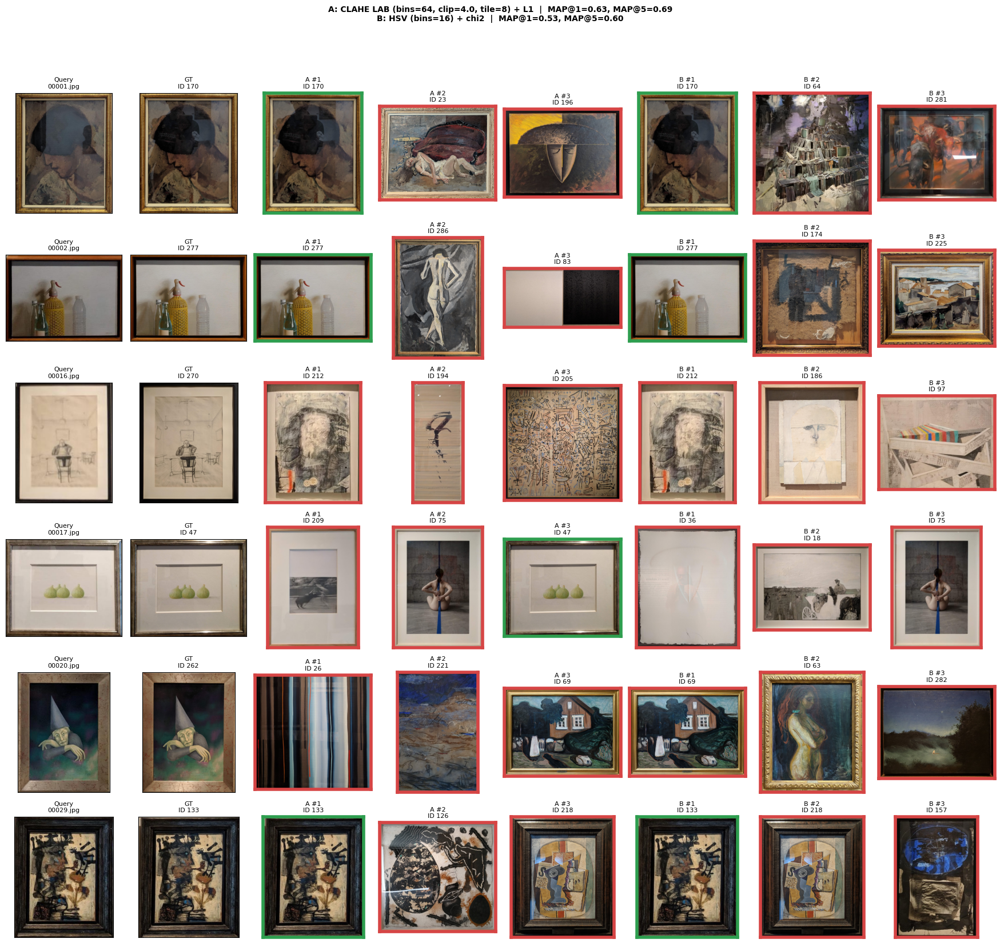

In [ ]:
import matplotlib.pyplot as plt

"""Qualitative check of the two best methods on QSD1 (the set with ground truth).
MAP@K gives one number per method, but not WHY a method fails. This plot shows it:
each row is a query, followed by its correct painting (GT) and the top-k results
of method A and method B. Green border = result is in the GT, red = it is not.
Uses leaderboard_all and per_query_all (default + grid-search configurations), so the legend shows
the exact parameters. By default it shows half queries where A fails at top-1 and half where it succeeds.
"""

def plot_best_methods(methods=None, n_queries=6, top_k=3, query_indices=None, seed=0, save_path=None):
    #methods: list of descriptor names ("M2 HSV": its best configuration and distance by MAP@5 is used)
    #         or (descriptor, parameters, distance) tuples. None = best config of the two best descriptors.
    #needs: leaderboard_all, per_query_all, actual_ids, bbdd_imgs, bbdd_ids, qsd1_imgs, qsd1_files
    top_k = min(top_k, 5)  #only the top-5 is stored per query
    if methods is None:
        methods = list(leaderboard_all.drop_duplicates(subset=["Descriptor"]).head(2)["Descriptor"])

    resolved = []  #(descriptor, parameters, distance, MAP@1, MAP@5)
    for m in methods:
        if isinstance(m, str):  #only descriptor given -> best row of leaderboard_all (already sorted by MAP@5, MAP@1)
            row = leaderboard_all[leaderboard_all["Descriptor"] == m].iloc[0]
        else:
            row = leaderboard_all[(leaderboard_all["Descriptor"] == m[0]) & (leaderboard_all["Parameters"] == m[1])
                                  & (leaderboard_all["Distance"] == m[2])].iloc[0]
        resolved.append((row["Descriptor"], row["Parameters"], row["Distance"], row["MAP@1"], row["MAP@5"]))

    def get_predictions(descriptor, parameters, distance):
        rows = per_query_all[(per_query_all["Descriptor"] == descriptor) & (per_query_all["Parameters"] == parameters)
                             & (per_query_all["Distance"] == distance)].set_index("Query").loc[qsd1_files]  #same order as queries
        return [[int(i) for i in ids] for ids in rows["Top 5 IDs"]]

    preds_by_method = [get_predictions(d, p, dist) for d, p, dist, _, _ in resolved]
    letters = [chr(ord("A") + i) for i in range(len(resolved))]
    id_to_idx = {int(i): idx for idx, i in enumerate(bbdd_ids)}

    if query_indices is None:
        #mix of queries: half where method A fails at top-1, half where it succeeds
        preds_a = preds_by_method[0]
        wrong = [q for q in range(len(actual_ids)) if preds_a[q][0] not in actual_ids[q]]
        right = [q for q in range(len(actual_ids)) if q not in wrong]
        rng = np.random.default_rng(seed)
        n_w = min(len(wrong), n_queries // 2)
        n_r = min(len(right), n_queries - n_w)
        query_indices = sorted(int(q) for q in list(rng.choice(wrong, n_w, replace=False)) + list(rng.choice(right, n_r, replace=False)))

    n_cols = 2 + top_k * len(resolved)
    fig, axes = plt.subplots(len(query_indices), n_cols,
                             figsize=(2.2 * n_cols, 2.8 * len(query_indices)), squeeze=False)

    for r, q in enumerate(query_indices):
        gt = actual_ids[q]
        cells = [(f"Query\n{qsd1_files[q]}", qsd1_imgs[q], None),
                 (f"GT\nID {gt[0]}", bbdd_imgs[id_to_idx[gt[0]]], None)]
        for letter, preds in zip(letters, preds_by_method):
            for rank, pid in enumerate(preds[q][:top_k]):
                cells.append((f"{letter} #{rank + 1}\nID {pid}", bbdd_imgs[id_to_idx[pid]], pid in gt))

        for c, (title, img, ok) in enumerate(cells):
            ax = axes[r, c]
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  #cv2 loads BGR
            ax.set_title(title, fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
            if ok is not None:  #green border = correct, red = wrong
                for sp in ax.spines.values():
                    sp.set_edgecolor("#2E9E4F" if ok else "#D64545")
                    sp.set_linewidth(4)

    clean = lambda name: re.sub(r"^M\d+\s+", "", name)  #"M2 HSV" -> "HSV", "M5 CLAHE LAB" -> "CLAHE LAB"
    legend = "\n".join(f"{l}: {clean(d)} ({p}) + {dist}  |  MAP@1={m1:.2f}, MAP@5={m5:.2f}"
                       for l, (d, p, dist, m1, m5) in zip(letters, resolved))
    fig.suptitle(legend, fontsize=10, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_best_methods(methods=["M5 CLAHE LAB", "M2 HSV"], n_queries=6, top_k=3,
                  save_path="./results/best_methods.png")

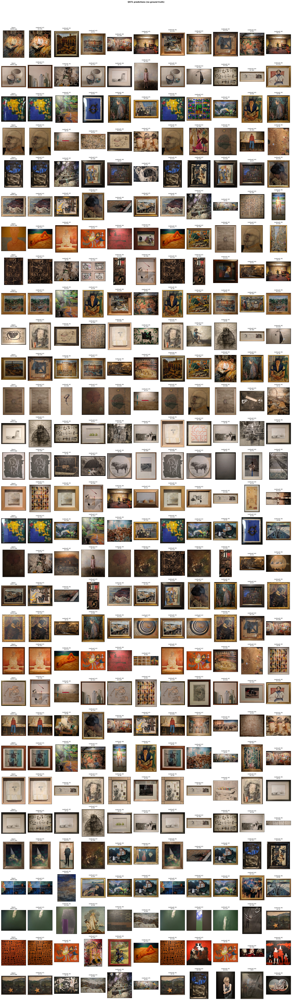

In [ ]:
"""
Check of the predictions on QST1 (blind test set, NO ground truth).
We cannot compute MAP here, so we only check that the results look plausible:
each row is a query followed by its top-k retrieved BBDD paintings (no green/red borders).
It also detects ordering mistakes: queries are read in the same natural order used to
generate the predictions, and an assert checks that both counts match.
Accepts one method (list of lists) or several as a dict {name: list of lists}.
"""

def plot_qst1_predictions(predictions, n_queries=6, top_k=5, query_indices=None, seed=0,
                          test_dir=None, save_path=None):
    #predictions: list of lists of BBDD ids (one method) or dict {method name: list of lists}
    #needs: qst1_path, return_number, read_image, bbdd_imgs, bbdd_ids
    test_dir = test_dir or qst1_path
    if not isinstance(predictions, dict):
        predictions = {"Method": predictions}
    names = list(predictions.keys())

    query_files = [f for f in os.listdir(test_dir) if f.lower().endswith(".jpg")]
    query_files.sort(key=return_number)  #same order used to generate the predictions
    for name, preds in predictions.items():
        assert len(preds) == len(query_files), f"{name}: {len(preds)} predictions vs {len(query_files)} queries"

    if query_indices is None:
        rng = np.random.default_rng(seed)
        query_indices = sorted(int(q) for q in rng.choice(len(query_files), min(n_queries, len(query_files)), replace=False))

    top_k = min(top_k, min(len(p[0]) for p in predictions.values()))
    id_to_idx = {int(i): idx for idx, i in enumerate(bbdd_ids)}
    n_cols = 1 + top_k * len(names)
    fig, axes = plt.subplots(len(query_indices), n_cols,
                             figsize=(2.2 * n_cols, 2.8 * len(query_indices)), squeeze=False)

    for r, q in enumerate(query_indices):
        cells = [(f"Query\n{query_files[q]}", read_image(os.path.join(test_dir, query_files[q])))]  #load only the shown queries
        for name in names:
            for rank, pid in enumerate(predictions[name][q][:top_k]):
                prefix = f"{name} " if len(names) > 1 else ""
                cells.append((f"{prefix}#{rank + 1}\nID {pid}", bbdd_imgs[id_to_idx[int(pid)]]))

        for c, (title, img) in enumerate(cells):
            ax = axes[r, c]
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))  #cv2 loads BGR
            ax.set_title(title, fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])

    fig.suptitle("QST1 predictions (no ground truth)", fontsize=11, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

plot_qst1_predictions(qst1_predictions, n_queries=30, top_k=5, save_path="./results/qst1_preview.png")

Queries where CLAHE-LAB ranks the correct BBDD image first, but HSV only finds it further down the top-5

In [ ]:
distance = "L1"   # distance used for both descriptors
top_k = 5         # top-five results are stored in per_query_all


def best_parameter_predictions(descriptor_name):
    rows = per_query_all[
        (per_query_all["Descriptor"] == descriptor_name)
        & (per_query_all["Parameters"] == best_parameters[descriptor_name])
        & (per_query_all["Distance"] == distance)
    ].set_index("Query").loc[qsd1_files]
    return [[int(image_id) for image_id in ids] for ids in rows["Top 5 IDs"]]

lab_preds = best_parameter_predictions("M5 CLAHE LAB")
hsv_preds = best_parameter_predictions("M2 HSV")
id_to_idx = {int(image_id): idx for idx, image_id in enumerate(bbdd_ids)}

# queries where CLAHE-LAB has the correct image at #1,
# and HSV has it inside the top-5 but NOT at #1
idxs = [
    query_index for query_index in range(len(actual_ids))
    if lab_preds[query_index][0] in actual_ids[query_index]
    and hsv_preds[query_index][0] not in actual_ids[query_index]
    and any(image_id in actual_ids[query_index] for image_id in hsv_preds[query_index][:top_k])
]

print(f"{len(idxs)} queries ({distance}): " + ", ".join(qsd1_files[query_index] for query_index in idxs))

if idxs:
    n_cols = 1 + 2 * top_k
    fig, axes = plt.subplots(len(idxs), n_cols,
                             figsize=(2.2 * n_cols, 2.8 * len(idxs)), squeeze=False)

    for row_index, query_index in enumerate(idxs):
        gt = actual_ids[query_index]
        cells = [(f"Query\n{qsd1_files[query_index]}\nGT ID {gt[0]}", qsd1_imgs[query_index], None)]
        for name, preds in [("CLAHE-LAB", lab_preds), ("HSV", hsv_preds)]:
            for rank, image_id in enumerate(preds[query_index][:top_k]):
                cells.append((f"{name} #{rank + 1}\nID {image_id}", bbdd_imgs[id_to_idx[int(image_id)]], image_id in gt))

        for axis, (title, image, correct) in zip(axes[row_index], cells):
            axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            axis.set_title(title, fontsize=8)
            axis.set_xticks([])
            axis.set_yticks([])
            if correct is None:
                axis.axis("off")
            else:
                for spine in axis.spines.values():
                    spine.set_edgecolor("#2E9E4F" if correct else "#D64545")
                    spine.set_linewidth(4)

    fig.suptitle(
        f"QSD1: CLAHE-LAB hits at #1, HSV hits only below #1 ({distance}, top-{top_k})\n"
        f"CLAHE-LAB: {best_parameters['M5 CLAHE LAB']} | HSV: {best_parameters['M2 HSV']}",
        fontsize=12,
        fontweight="bold",
    )
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
